# 08 Hypothesis Tests

**Question:** Which differences are real and which are noise?

Task 2, step 8: **pick three hypotheses, such as "mobile CTR is lower than desktop", and test each with a two-proportion z-test. Report the effect size and confidence interval, not only the p-value.**

**The three hypotheses** (edit `HYPOTHESES` in Cell 4 to test your own):
1. **H1:** mobile and tablet CTR is **lower** than desktop CTR
2. **H2:** evening CTR (18:00–23:59) is **higher** than daytime CTR (08:00–17:59)
3. **H3:** impressions on slots **with a floor price** have a **higher** CTR than slots without one (are priced slots better inventory?)

**What is reported for each:**
* **the two rates**, each with a 95% Wilson interval, and the group sizes
* **effect size**: the absolute difference in percentage points with a 95% CI, the **relative lift** with a 95% CI, and **Cohen's h**. Cohen's h is a standard effect size for proportions: 0.2 is small and 0.5 medium. CTR effects are almost always "small" on this scale, so read the lift too.
* **z and p-value**: one-sided in the hypothesis's direction, plus two-sided
* **minimum detectable effect** at 80% power: the smallest difference this sample could reliably detect. A non-significant result with a large MDE means *not enough data*, not *no effect*.
* **within-campaign check**: the same comparison inside each campaign, and a **Cochran–Mantel–Haenszel** (CMH) test that pools those within-campaign comparisons. If the pooled result disagrees with the within-campaign result, campaign mix is driving it (Simpson's paradox, Notebook 09).
* **multiple comparisons**: 3 pooled tests plus 15 per-campaign tests is many. The per-campaign p-values are corrected with Benjamini–Hochberg.

**How the z-test works:** under H0 the two groups share one CTR, *p̂*. Then `z = (p_A − p_B) / sqrt(p̂(1 − p̂)(1/n_A + 1/n_B))`, which is approximately standard normal. The CI for the difference uses the unpooled standard error, `sqrt(p_A(1 − p_A)/n_A + p_B(1 − p_B)/n_B)`.

Setup, user-agent parsing and click linking are the same as Notebook 05. The database is opened read-only.

### Setup

In [1]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import math, os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

KILL_STALE = False
RUN_WIN_RATE = True          # win rate needs one pass over the 53M bids (a few minutes)
FOCUS = 1458                 # the campaign shown in detail; change to any advertiser_id
MIN_EXPECTED_CLICKS = 30     # CTR shown when imps >= this / overall CTR
MIN_CLICKS_CVR, MIN_CONVS_CPA, MIN_BIDS_WR = 30, 10, 1_000
TOP_TAGS = 30                # user tags shown (by volume)
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert {"typed_imp", "typed_clk", "typed_conv"} <= views, "Run the loading cells first"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    t = lambda c, typ="BIGINT": f"TRY_CAST(nullif(nullif({c}, ''), 'null') AS {typ}) AS {c}"
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT " + ", ".join(
        [t(c) for c in ["advertiser_id", "region", "ad_exchange", "ad_slot_width", "ad_slot_height",
                        "ad_slot_visibility", "ad_slot_format", "ad_slot_floor_price"]] + ["user_agent", "user_tags"])
        + " FROM read_parquet([" + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt in memory from", len(files), "Parquet files")

# optional readable names, if the dataset's lookup files are anywhere under data/
def lookup(name):
    for p in (PROJECT_ROOT / "data").rglob(name):
        d = {}
        for line in p.read_text(encoding="utf-8", errors="replace").splitlines():
            parts = line.split("\t")
            if len(parts) >= 2 and parts[0].strip().lstrip("-").isdigit():
                d[parts[0].strip()] = parts[1].strip()
        return d
    return {}
REGION_NAMES, TAG_NAMES = lookup("region.en.txt"), lookup("user.profile.tags.en.txt")
print("region names:", "found" if REGION_NAMES else "not found (codes shown)",
      "| tag names:", "found" if TAG_NAMES else "not found (codes shown)")

def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

def ztest(k1, n1, k2, n2):
    """Two-proportion z-test (pooled), two-sided p-value. Returns (z, p)."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    se = math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    if se == 0:
        return np.nan, np.nan
    z = (p1 - p2) / se
    return z, math.erfc(abs(z) / math.sqrt(2))

def bh(p):
    """Benjamini-Hochberg q-values (NaN stays NaN)."""
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.sum():
        pv = p[ok]
        o = np.argsort(pv)
        r = pv[o] * ok.sum() / np.arange(1, ok.sum() + 1)
        r = np.minimum.accumulate(r[::-1])[::-1]
        res = np.empty_like(pv)
        res[o] = np.clip(r, 0, 1)
        out[ok] = res
    return out

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
BLUE, ORANGE, GREY, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved)")
print("Data:", DATA_SOURCE)
RUN_WIN_RATE = False   # bids are not needed here: parse only the impression user agents

region names: found | tag names: found
Data: ipinyou.duckdb (the loading notebook's database)


### 1. Device from the user agent

In [2]:
# CELL 2: user-agent lookup
t0 = time.time()
ua_src = "SELECT DISTINCT user_agent FROM typed_imp" + (" UNION SELECT DISTINCT user_agent FROM typed_bid" if RUN_WIN_RATE else "")
con.execute(f"""
CREATE OR REPLACE TEMP TABLE ua_map AS
WITH u AS ({ua_src}), l AS (SELECT user_agent, lower(coalesce(user_agent, '')) AS ua FROM u)
SELECT user_agent,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'ipad|tablet') THEN 'tablet'
       WHEN regexp_matches(ua, 'mobile|android|iphone|ipod|windows phone|symbian|blackberry|nokia|ucweb|opera mini|midp') THEN 'mobile'
       ELSE 'desktop' END AS device,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'iphone|ipad|ipod') THEN 'iOS'
       WHEN regexp_matches(ua, 'android') THEN 'Android'
       WHEN regexp_matches(ua, 'windows nt 5\\.1|windows xp') THEN 'Windows XP'
       WHEN regexp_matches(ua, 'windows nt 6\\.1') THEN 'Windows 7'
       WHEN regexp_matches(ua, 'windows nt 6\\.[23]') THEN 'Windows 8'
       WHEN regexp_matches(ua, 'windows nt 6\\.0') THEN 'Windows Vista'
       WHEN regexp_matches(ua, 'windows') THEN 'Windows (other)'
       WHEN regexp_matches(ua, 'mac os|macintosh') THEN 'macOS'
       WHEN regexp_matches(ua, 'linux') THEN 'Linux'
       ELSE 'other' END AS os,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'metasr|sogou') THEN 'Sogou'
       WHEN regexp_matches(ua, '360se|360ee|360browser') THEN '360'
       WHEN regexp_matches(ua, 'maxthon') THEN 'Maxthon'
       WHEN regexp_matches(ua, 'theworld') THEN 'TheWorld'
       WHEN regexp_matches(ua, 'qqbrowser|tencenttraveler') THEN 'QQ'
       WHEN regexp_matches(ua, 'ucbrowser|ucweb') THEN 'UC'
       WHEN regexp_matches(ua, 'opera|opr/') THEN 'Opera'
       WHEN regexp_matches(ua, 'chrome|crios') THEN 'Chrome'
       WHEN regexp_matches(ua, 'firefox') THEN 'Firefox'
       WHEN regexp_matches(ua, 'msie|trident') THEN 'IE'
       WHEN regexp_matches(ua, 'safari') THEN 'Safari'
       ELSE 'other' END AS browser
FROM l""")
n_ua = q("SELECT count(*) AS n FROM ua_map").n[0]
print(f"{n_ua:,} distinct user agents parsed ({time.time() - t0:.0f}s)")
display(q("""SELECT device, os, browser, count(*) AS distinct_strings FROM ua_map GROUP BY ALL
             ORDER BY distinct_strings DESC LIMIT 12"""))

459,647 distinct user agents parsed (0s)


,device,os,browser,distinct_strings
0,desktop,Windows XP,IE,222238
1,desktop,Windows 7,IE,53816
2,desktop,Windows XP,QQ,28571
3,desktop,Windows XP,Sogou,27296
4,desktop,Windows 7,Sogou,15969
5,mobile,Android,Safari,12905
6,desktop,Windows XP,360,11551
7,tablet,Windows 7,IE,10454
8,desktop,Windows XP,TheWorld,8406
9,desktop,Windows 7,QQ,7302


### 2. Link clicks and conversions (the Notebook 02 rule)

In [3]:
# CELL 3: linking -> flags per impression
con.execute("""
CREATE OR REPLACE TEMP TABLE imp_c AS
SELECT DISTINCT bid_id, ipinyou_id, timestamp AS imp_ts, hash(bid_id, ipinyou_id, timestamp) AS imp_key
FROM typed_imp WHERE bid_id IN (SELECT bid_id FROM typed_clk UNION SELECT bid_id FROM typed_conv)""")
for log in ["clk", "conv"]:
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    WITH e AS (SELECT row_number() OVER () AS ev_id, bid_id, ipinyou_id, timestamp AS ev_ts
               FROM (SELECT DISTINCT * FROM typed_{log})),
    m1 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ipinyou_id = i.ipinyou_id AND e.ev_ts >= i.imp_ts),
    m2 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i ON e.bid_id = i.bid_id AND e.ev_ts >= i.imp_ts),
    m3 AS (SELECT e.ev_id, arg_min(i.imp_key, abs(epoch(e.ev_ts) - epoch(i.imp_ts))) AS imp_key
           FROM e JOIN imp_c i USING (bid_id) GROUP BY 1)
    SELECT coalesce(m1.imp_key, m2.imp_key, m3.imp_key) AS imp_key
    FROM e LEFT JOIN m1 USING (ev_id) LEFT JOIN m2 USING (ev_id) LEFT JOIN m3 USING (ev_id)""")
con.execute("""
CREATE OR REPLACE TEMP TABLE flags AS
WITH k AS (SELECT DISTINCT imp_key FROM clk_m WHERE imp_key IS NOT NULL),
     v AS (SELECT DISTINCT imp_key FROM conv_m WHERE imp_key IS NOT NULL)
SELECT coalesce(k.imp_key, v.imp_key) AS imp_key, (k.imp_key IS NOT NULL)::INT AS clicked,
       (v.imp_key IS NOT NULL)::INT AS converted, (k.imp_key IS NOT NULL AND v.imp_key IS NOT NULL)::INT AS pc_converted
FROM k FULL JOIN v USING (imp_key)""")
display(q("SELECT sum(clicked) AS clicked_imps, sum(converted) AS converted_imps, sum(pc_converted) AS postclick_converted FROM flags"))

,clicked_imps,converted_imps,postclick_converted
0,8751.0,391.0,391.0


In [4]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

### 3. Define the hypotheses

Each hypothesis has two groups, A and B, written as SQL filters over these columns: `device`, `os`, `browser`, `hour`, `floor`, `slot_size`, `ad_exchange`, `region`, `visibility`. `metric` is `ctr` (clicked impressions / impressions) or `cvr` (post-click conversions / clicks). `alternative` is the direction claimed for A vs B: `smaller`, `larger` or `two-sided`.

In [5]:
# CELL 4: the hypotheses (edit freely)
HYPOTHESES = [
    dict(name="H1", claim="Mobile and tablet CTR is lower than desktop CTR", metric="ctr",
         a="device IN ('mobile', 'tablet')", a_label="mobile + tablet",
         b="device = 'desktop'", b_label="desktop", alternative="smaller"),
    dict(name="H2", claim="Evening CTR (18-24h) is higher than daytime CTR (8-18h)", metric="ctr",
         a="hour BETWEEN 18 AND 23", a_label="evening 18-24h",
         b="hour BETWEEN 8 AND 17", b_label="daytime 8-18h", alternative="larger"),
    dict(name="H3", claim="Slots with a floor price have a higher CTR than slots without one", metric="ctr",
         a="floor > 0", a_label="floor > 0",
         b="floor = 0", b_label="no floor", alternative="larger"),
]

### 4. Count successes and trials per group, per campaign (one pass over the impressions)

In [6]:
# CELL 5: counts
parts = []
for h in HYPOTHESES:
    k_col, n_col = ("clicked", "1") if h["metric"] == "ctr" else ("pc", "clicked")
    for g in ("a", "b"):
        parts += [f"sum({n_col}) FILTER (WHERE {h[g]}) AS \"{h['name']}_{g}_n\"",
                  f"sum({k_col}) FILTER (WHERE {h[g]}) AS \"{h['name']}_{g}_k\""]
t0 = time.time()
cnt = q(f"""
    WITH s AS (
        SELECT i.advertiser_id, coalesce(f.clicked, 0) AS clicked, coalesce(f.pc_converted, 0) AS pc,
               u.device, u.os, u.browser, hour(i.timestamp) AS hour, i.ad_slot_floor_price AS floor,
               CAST(i.ad_slot_width AS VARCHAR) || 'x' || CAST(i.ad_slot_height AS VARCHAR) AS slot_size,
               i.ad_exchange, i.region, i.ad_slot_visibility AS visibility
        FROM typed_imp i
        LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
        LEFT JOIN ua_map u USING (user_agent))
    SELECT advertiser_id, {", ".join(parts)} FROM s GROUP BY advertiser_id ORDER BY 1""").fillna(0)
print(f"counted in {time.time() - t0:.0f}s")
display(cnt.set_index("advertiser_id").T)

counted in 1s


advertiser_id,1458,3358,3386,3427,3476
H1_a_n,97655.0,92531.0,79787.0,73700.0,27442.0
H1_a_k,317.0,375.0,405.0,325.0,37.0
H1_b_n,2984940.0,1649278.0,2767640.0,2519724.0,1942814.0
H1_b_k,2117.0,947.0,1657.0,1581.0,986.0
H2_a_n,1046731.0,581351.0,981277.0,809998.0,428108.0
H2_a_k,898.0,516.0,812.0,674.0,255.0
H2_b_n,1615330.0,629132.0,1407176.0,1380568.0,1194393.0
H2_b_k,1181.0,369.0,914.0,931.0,605.0
H3_a_n,2045336.0,829142.0,2176840.0,1896459.0,1411065.0
H3_a_k,1672.0,477.0,1220.0,1197.0,762.0


### 5. The tests

In [7]:
# CELL 6: two-proportion z-tests, effect sizes, MDE, per-campaign tests, CMH
from math import erfc, sqrt, asin
Z95, Z80 = 1.959964, 0.841621
norm_sf = lambda z: 0.5 * erfc(z / sqrt(2))

def two_prop(k1, n1, k2, n2, alternative="two-sided"):
    p1, p2 = k1 / n1, k2 / n2
    pp = (k1 + k2) / (n1 + n2)
    se0 = sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se0 if se0 > 0 else np.nan
    p_two = erfc(abs(z) / sqrt(2)) if z == z else np.nan
    p_one = norm_sf(z) if alternative == "larger" else (norm_sf(-z) if alternative == "smaller" else p_two)
    se1 = sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    d = p1 - p2
    lo1, hi1 = wilson(k1, n1)
    lo2, hi2 = wilson(k2, n2)
    return {"n_A": n1, "k_A": k1, "rate_A": p1, "rate_A_lo": float(lo1), "rate_A_hi": float(hi1),
            "n_B": n2, "k_B": k2, "rate_B": p2, "rate_B_lo": float(lo2), "rate_B_hi": float(hi2),
            "diff_pp": 100 * d, "diff_pp_lo": 100 * (d - Z95 * se1), "diff_pp_hi": 100 * (d + Z95 * se1),
            "rel_lift": d / p2 if p2 else np.nan,
            "rel_lift_lo": (d - Z95 * se1) / p2 if p2 else np.nan, "rel_lift_hi": (d + Z95 * se1) / p2 if p2 else np.nan,
            "cohens_h": 2 * asin(sqrt(p1)) - 2 * asin(sqrt(p2)), "z": z,
            "p_one_sided": p_one, "p_two_sided": p_two,
            "mde_pp_80pct_power": 100 * (Z95 + Z80) * sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))}

def cmh(rows):
    """Cochran-Mantel-Haenszel across campaigns: pooled odds ratio (MH), test of 'no association', and the
    MH-weighted risk difference. rows: list of (kA, nA, kB, nB)."""
    num = den = stat_num = var = rd_num = rd_den = 0.0
    for kA, nA, kB, nB in rows:
        if nA == 0 or nB == 0:
            continue
        a, b, c, d = kA, nA - kA, kB, nB - kB
        N = nA + nB
        num += a * d / N
        den += b * c / N
        m1 = a + c
        E = nA * m1 / N
        V = nA * nB * m1 * (N - m1) / (N * N * (N - 1)) if N > 1 else 0
        stat_num += a - E
        var += V
        w = nA * nB / N
        rd_num += w * (kA / nA - kB / nB)
        rd_den += w
    chi2 = (abs(stat_num) - 0.5) ** 2 / var if var > 0 else np.nan
    return {"cmh_odds_ratio": num / den if den else np.nan,
            "cmh_p": erfc(sqrt(chi2 / 2)) if chi2 == chi2 else np.nan,
            "within_campaign_diff_pp": 100 * rd_num / rd_den if rd_den else np.nan}

pooled, per = [], []
for h in HYPOTHESES:
    nm = h["name"]
    c = cnt[[f"{nm}_a_k", f"{nm}_a_n", f"{nm}_b_k", f"{nm}_b_n"]].astype(float)
    t = c.sum()
    r = {"name": nm, "claim": h["claim"], "metric": h["metric"].upper(), "A": h["a_label"], "B": h["b_label"],
         "alternative": h["alternative"]}
    if min(t[f"{nm}_a_n"], t[f"{nm}_b_n"]) == 0:
        pooled.append({**r, "verdict": "cannot test: a group is empty (check the filter values in Notebook 05)"})
        continue
    res = two_prop(t[f"{nm}_a_k"], t[f"{nm}_a_n"], t[f"{nm}_b_k"], t[f"{nm}_b_n"], h["alternative"])
    res.update(cmh(c.values.tolist()))
    supported = res["p_one_sided"] < 0.05
    if supported:
        res["verdict"] = "supported"
    elif res["p_two_sided"] < 0.05:
        res["verdict"] = "rejected: the difference is significant but goes the other way"
    elif abs(res["diff_pp"]) < res["mde_pp_80pct_power"]:
        res["verdict"] = "not supported (too little data to detect an effect this size)"
    else:
        res["verdict"] = "not supported"
    same_dir = np.sign(res["diff_pp"]) == np.sign(res["within_campaign_diff_pp"])
    res["within_campaign_check"] = ("same direction within campaigns" if same_dir else
                                    "REVERSES within campaigns: mix effect, see Notebook 09")
    pooled.append({**r, **res})
    for adv, row in zip(cnt.advertiser_id, c.values):
        kA, nA, kB, nB = row
        if nA > 0 and nB > 0:
            per.append({"name": nm, "campaign": adv, **two_prop(kA, nA, kB, nB, h["alternative"])})

TESTS = pd.DataFrame(pooled)
PER = pd.DataFrame(per)
if len(PER):
    o = np.argsort(PER.p_one_sided.values)
    m = len(o)
    q_ = PER.p_one_sided.values[o] * m / np.arange(1, m + 1)
    q_ = np.minimum.accumulate(q_[::-1])[::-1]
    PER["q_BH"] = np.empty(m)
    PER.loc[PER.index[o], "q_BH"] = np.clip(q_, 0, 1)

show = ["name", "claim", "A", "B", "n_A", "rate_A", "n_B", "rate_B", "diff_pp", "diff_pp_lo", "diff_pp_hi",
        "rel_lift", "rel_lift_lo", "rel_lift_hi", "cohens_h", "z", "p_one_sided", "p_two_sided",
        "mde_pp_80pct_power", "cmh_odds_ratio", "cmh_p", "within_campaign_diff_pp", "verdict", "within_campaign_check"]
fmt = {"n_A": "{:,.0f}", "n_B": "{:,.0f}", "rate_A": "{:.3%}", "rate_B": "{:.3%}", "diff_pp": "{:+.4f}",
       "diff_pp_lo": "{:+.4f}", "diff_pp_hi": "{:+.4f}", "rel_lift": "{:+.1%}", "rel_lift_lo": "{:+.1%}",
       "rel_lift_hi": "{:+.1%}", "cohens_h": "{:+.4f}", "z": "{:+.2f}", "p_one_sided": "{:.2g}", "p_two_sided": "{:.2g}",
       "mde_pp_80pct_power": "{:.4f}", "cmh_odds_ratio": "{:.3f}", "cmh_p": "{:.2g}", "within_campaign_diff_pp": "{:+.4f}"}
print("Pooled tests (all campaigns), one row per hypothesis. diff_pp = A − B in percentage points:")
display(TESTS[[c for c in show if c in TESTS]].T.style.format(lambda v: v if isinstance(v, str) else f"{v:,.4g}"))
print("Same comparison inside each campaign (q_BH = Benjamini-Hochberg over these tests):")
display(PER[["name", "campaign", "n_A", "rate_A", "n_B", "rate_B", "diff_pp", "diff_pp_lo", "diff_pp_hi", "rel_lift",
             "z", "p_one_sided", "q_BH", "mde_pp_80pct_power"]]
        .style.format({**fmt, "q_BH": "{:.2g}"}).hide(axis="index"))

Pooled tests (all campaigns), one row per hypothesis. diff_pp = A − B in percentage points:


,0,1,2
name,H1,H2,H3
claim,Mobile and tablet CTR is lower than desktop CTR,Evening CTR (18-24h) is higher than daytime CTR (8-18h),Slots with a floor price have a higher CTR than slots without one
A,mobile + tablet,evening 18-24h,floor > 0
B,desktop,daytime 8-18h,no floor
n_A,3.711e+05,3.847e+06,8.359e+06
rate_A,0.003931,0.00082,0.0006374
n_B,1.186e+07,6.227e+06,3.878e+06
rate_B,0.0006143,0.0006424,0.0008826
diff_pp,0.3317,0.01776,-0.02452
diff_pp_lo,0.3115,0.01428,-0.02794


Same comparison inside each campaign (q_BH = Benjamini-Hochberg over these tests):


name,campaign,n_A,rate_A,n_B,rate_B,diff_pp,diff_pp_lo,diff_pp_hi,rel_lift,z,p_one_sided,q_BH,mde_pp_80pct_power
H1,1458,"97,655",0.325%,"2,984,940",0.071%,+0.2537,+0.2179,+0.2895,+357.7%,+27.77,1,1,0.0256
H1,3358,"92,531",0.405%,"1,649,278",0.057%,+0.3479,+0.3068,+0.3889,+605.8%,+37.39,1,1,0.0261
H1,3386,"79,787",0.508%,"2,767,640",0.060%,+0.4477,+0.3983,+0.4971,+747.8%,+46.35,1,1,0.0271
H1,3427,"73,700",0.441%,"2,519,724",0.063%,+0.3782,+0.3303,+0.4262,+602.8%,+37.35,1,1,0.0284
H1,3476,"27,442",0.135%,"1,942,814",0.051%,+0.0841,+0.0405,+0.1276,+165.7%,+6.07,1,1,0.0388
H2,1458,"1,046,731",0.086%,"1,615,330",0.073%,+0.0127,+0.0057,+0.0197,+17.3%,+3.62,0.00015,0.00056,0.0098
H2,3358,"581,351",0.089%,"629,132",0.059%,+0.0301,+0.0204,+0.0398,+51.3%,+6.12,4.6e-10,6.9e-09,0.0138
H2,3386,"981,277",0.083%,"1,407,176",0.065%,+0.0178,+0.0107,+0.0249,+27.4%,+5.04,2.4e-07,1.8e-06,0.0099
H2,3427,"809,998",0.083%,"1,380,568",0.067%,+0.0158,+0.0081,+0.0234,+23.4%,+4.17,1.6e-05,7.8e-05,0.0106
H2,3476,"428,108",0.060%,"1,194,393",0.051%,+0.0089,+0.0006,+0.0173,+17.6%,+2.17,0.015,0.037,0.0115


/var/folders/vr/5sr6q8096vd7rsf7r7sy60dw0000gn/T/ipykernel_14448/2383724138.py:25: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


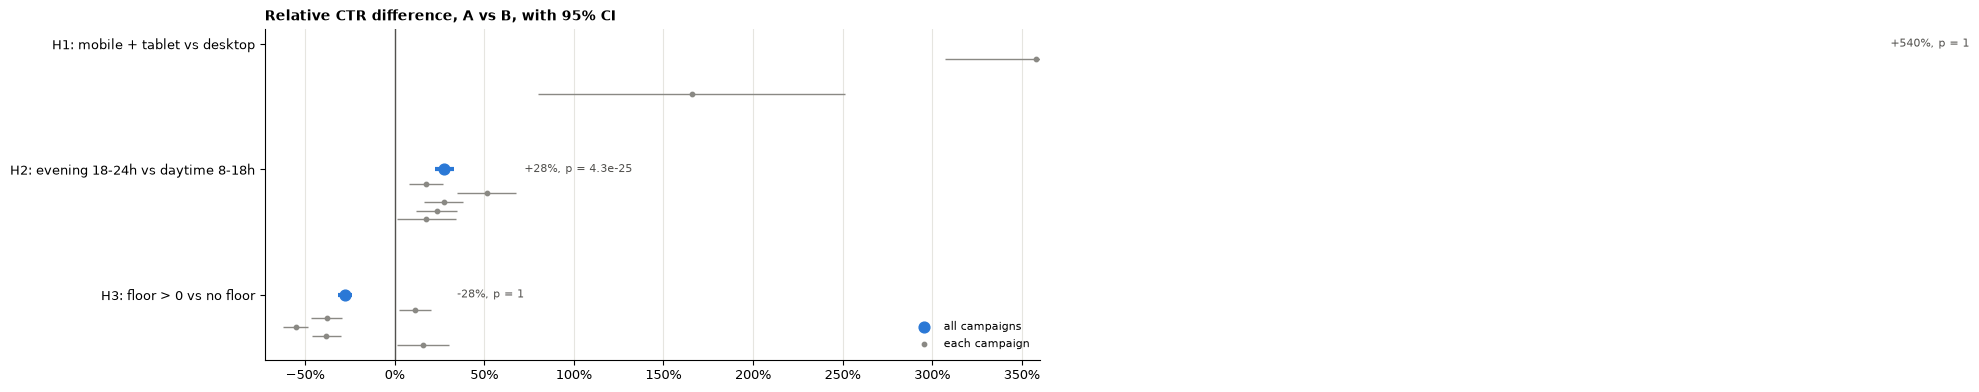

In [8]:
# CELL 7: chart - relative lift with 95% CI, pooled (big) and per campaign (small)
if plt and len(PER):
    fig, ax = plt.subplots(figsize=(10, 1.3 + 1.0 * len(TESTS)))
    ylab = []
    for i, r in enumerate(TESTS.dropna(subset=["rel_lift"]).itertuples()):
        y = len(TESTS) - 1 - i
        ax.hlines(y, r.rel_lift_lo, r.rel_lift_hi, color=BLUE, lw=3)
        ax.scatter(r.rel_lift, y, color=BLUE, s=60, zorder=3, label="all campaigns" if i == 0 else None)
        d = PER[PER.name == r.name]
        for j, pr in enumerate(d.itertuples()):
            yy = y - 0.12 - 0.07 * j
            ax.hlines(yy, pr.rel_lift_lo, pr.rel_lift_hi, color=GREY, lw=1)
            ax.scatter(pr.rel_lift, yy, color=GREY, s=10, zorder=3, label="each campaign" if (i == 0 and j == 0) else None)
        ax.text(max(r.rel_lift_hi, d.rel_lift_hi.max() if len(d) else r.rel_lift_hi), y,
                f"  {r.rel_lift:+.0%}, p = {r.p_one_sided:.2g}", va="center", fontsize=8, color=INK2)
        ylab.append((y, f"{r.name}: {r.A} vs {r.B}"))
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks([y for y, _ in ylab], [l for _, l in ylab])
    ax.xaxis.set_major_formatter(mt.PercentFormatter(1.0))
    ax.set_xlim(left=max(-1, min(TESTS.rel_lift_lo.min(), PER.rel_lift_lo.min()) - 0.1),
                right=min(3, max(TESTS.rel_lift_hi.max(), PER.rel_lift_hi.max())) + 0.6)
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_title("Relative CTR difference, A vs B, with 95% CI")
    fig.tight_layout()
    save(fig, "08_hypotheses")
    plt.show()

## Findings

Generated from the numbers above.

In [9]:
# CELL 8: findings + story candidates
F, cands = [], []
for r in TESTS.itertuples():
    if not hasattr(r, "rel_lift") or r.rel_lift != r.rel_lift:
        F.append(f"**{r.name}: {r.claim}.** {r.verdict}")
        continue
    sig_c = PER[(PER.name == r.name) & (PER.q_BH < 0.05)]
    F.append(f"**{r.name}: {r.claim}. {r.verdict.capitalize()}.** {r.A}: {r.rate_A:.3%} (n = {r.n_A:,.0f}) vs {r.B}: "
             f"{r.rate_B:.3%} (n = {r.n_B:,.0f}). Difference {r.diff_pp:+.4f} pp (95% CI {r.diff_pp_lo:+.4f} to "
             f"{r.diff_pp_hi:+.4f}), a {r.rel_lift:+.0%} relative lift (CI {r.rel_lift_lo:+.0%} to {r.rel_lift_hi:+.0%}); "
             f"Cohen's h = {r.cohens_h:+.3f}; z = {r.z:+.2f}, one-sided p = {r.p_one_sided:.3g}. Within campaigns: "
             f"{r.within_campaign_check} (CMH p = {r.cmh_p:.2g}); significant in {len(sig_c)} of "
             f"{(PER.name == r.name).sum()} campaigns after correction.")
    cands.append({"title": f"{r.name}: {r.claim}: {r.verdict.split(' (')[0]}",
                  "number": f"{r.A} {r.rate_A:.3%} vs {r.B} {r.rate_B:.3%}: {r.rel_lift:+.0%} (95% CI {r.rel_lift_lo:+.0%} "
                            f"to {r.rel_lift_hi:+.0%}), p = {r.p_one_sided:.3g}",
                  "chart": "08_hypotheses.png", "confidence": conf_from_p(r.p_one_sided),
                  "meaning": ("A real difference worth acting on with a bid adjustment, after a controlled test."
                              if r.p_one_sided < 0.05 and "same" in r.within_campaign_check else
                              "Not a reliable lever: don't move budget on this difference."),
                  "_effect": abs(r.z) if r.z == r.z else 0})
F.append("**Reading the results:** a tiny p-value with a small Cohen's h means the effect is real but modest. With "
         "millions of impressions, even small differences become significant, so judge the lift and its interval "
         "against the cost of acting on it.")
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
cands = sorted(cands, key=lambda c: -c.pop("_effect"))
save_story("08_hypothesis_tests", cands)

1. **H1: Mobile and tablet CTR is lower than desktop CTR. Rejected: the difference is significant but goes the other way.** mobile + tablet: 0.393% (n = 371,115) vs desktop: 0.061% (n = 11,864,396). Difference +0.3317 pp (95% CI +0.3115 to +0.3519), a +540% relative lift (CI +507% to +573%); Cohen's h = +0.076; z = +74.45, one-sided p = 1. Within campaigns: same direction within campaigns (CMH p = 0); significant in 0 of 5 campaigns after correction.
2. **H2: Evening CTR (18-24h) is higher than daytime CTR (8-18h). Supported.** evening 18-24h: 0.082% (n = 3,847,465) vs daytime 8-18h: 0.064% (n = 6,226,599). Difference +0.0178 pp (95% CI +0.0143 to +0.0212), a +28% relative lift (CI +22% to +33%); Cohen's h = +0.007; z = +10.28, one-sided p = 4.28e-25. Within campaigns: same direction within campaigns (CMH p = 9e-21); significant in 5 of 5 campaigns after correction.
3. **H3: Slots with a floor price have a higher CTR than slots without one. Rejected: the difference is significant but goes the other way.** floor > 0: 0.064% (n = 8,358,842) vs no floor: 0.088% (n = 3,878,245). Difference -0.0245 pp (95% CI -0.0279 to -0.0211), a -28% relative lift (CI -32% to -24%); Cohen's h = -0.009; z = -14.93, one-sided p = 1. Within campaigns: same direction within campaigns (CMH p = 9.3e-48); significant in 2 of 5 campaigns after correction.
4. **Reading the results:** a tiny p-value with a small Cohen's h means the effect is real but modest. With millions of impressions, even small differences become significant, so judge the lift and its interval against the cost of acting on it.

Saved 3 story candidate(s) to reports/findings/08_hypothesis_tests.json
